<a href="https://colab.research.google.com/github/Andrew35780/dap-2024/blob/main/les06/lab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторная работа №6. Линейная регрессия

Выполните следующие задания:

1. Откройте в файл в Google Colab (используйте собственный форк репозитория).
2. Решите задачи.
3. Сохраните результат в ваш репозиторий github в директорию ./les06
4. Создайте pull request в репозиторий https://github.com/chebotarevsa/dap-2024. Название pull request должно иметь формат "<Номер лабораторной работы>  <Номер группы> <ФИО>"
5. Сдайте работу в системе "Пегас", в отчет укажите ссылку на pull request

Набор данных Diabetes (Диабет) содержит 442 образца с 10-ю признаками: возраст, пол, индекс массы тела, средний показатель давления крови и шесть измерений сыворотки крови. Целевое значение - количественный показатель прогрессирования заболевания через год после анализов.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## Извлечение данных

In [2]:
from sklearn import datasets
diabetes = datasets.load_diabetes()

1. Выведете описание набора данных и наименование признаков.

In [61]:
from sklearn import datasets

diabetes = datasets.load_diabetes()

print("=== Информация о наборе данных ===")
print(f"Тип объекта: {type(diabetes)}")
print(f"Количество образцов: {diabetes.data.shape[0]}")
print(f"Количество признаков: {diabetes.data.shape[1]}")

print("\n=== Описание набора данных ===")
print(diabetes.DESCR)

print("\n=== Названия признаков ===")
for i, name in enumerate(diabetes.feature_names, start=1):
    print(f"{i}. {name}")

print("\n=== Первые 5 целевых значений ===")
print(diabetes.target[:5])

=== Информация о наборе данных ===
Тип объекта: <class 'sklearn.utils._bunch.Bunch'>
Количество образцов: 442
Количество признаков: 10

=== Описание набора данных ===
.. _diabetes_dataset:

Diabetes dataset
----------------

Ten baseline variables, age, sex, body mass index, average blood
pressure, and six blood serum measurements were obtained for each of n =
442 diabetes patients, as well as the response of interest, a
quantitative measure of disease progression one year after baseline.

**Data Set Characteristics:**

:Number of Instances: 442

:Number of Attributes: First 10 columns are numeric predictive values

:Target: Column 11 is a quantitative measure of disease progression one year after baseline

:Attribute Information:
    - age     age in years
    - sex
    - bmi     body mass index
    - bp      average blood pressure
    - s1      tc, total serum cholesterol
    - s2      ldl, low-density lipoproteins
    - s3      hdl, high-density lipoproteins
    - s4      tch, total

### Подготовка данных

2. Из загруженного набора данных создайте DataFrame, содержащий как признаки, так и целевое значение. Выведите первые 5 строк набора.

In [13]:
diabetes_df = pd.DataFrame(diabetes.data, columns=diabetes.feature_names)
diabetes_df['target'] = diabetes.target

print(diabetes_df.head(5))

        age       sex       bmi        bp        s1        s2        s3  \
0  0.038076  0.050680  0.061696  0.021872 -0.044223 -0.034821 -0.043401   
1 -0.001882 -0.044642 -0.051474 -0.026328 -0.008449 -0.019163  0.074412   
2  0.085299  0.050680  0.044451 -0.005670 -0.045599 -0.034194 -0.032356   
3 -0.089063 -0.044642 -0.011595 -0.036656  0.012191  0.024991 -0.036038   
4  0.005383 -0.044642 -0.036385  0.021872  0.003935  0.015596  0.008142   

         s4        s5        s6  target  
0 -0.002592  0.019907 -0.017646   151.0  
1 -0.039493 -0.068332 -0.092204    75.0  
2 -0.002592  0.002861 -0.025930   141.0  
3  0.034309  0.022688 -0.009362   206.0  
4 -0.002592 -0.031988 -0.046641   135.0  


3. Выведете информацию о типах данных в наборе. Имеются ли в наборе категориальные признаки? Имеются ли в наборе данные имеющие значение null?

In [63]:
"""
diabetes_df.info()
print(f"\nВ наборе отсутствуют категориальные признаки\n")
print(f"-----------------\n")

print(diabetes_df.isnull().sum())
print(f"\nВ наборе отсутствуют данные имеющие значения null")
"""

#OR

print("=== Информация о столбцах ===")
diabetes_df.info()

print("\n=== Количество пропущенных значений ===")
missing_values = diabetes_df.isnull().sum()
print(missing_values.to_string())

print("\nЕсть ли пропущенные значения?")
print("Да" if diabetes_df.isnull().any().any() else "Нет")

categorical_columns = diabetes_df.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("\nСтолбцы с категориальными типами pandas:")
print(categorical_columns if categorical_columns else "Не обнаружены")

=== Информация о столбцах ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 442 entries, 0 to 441
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   age     442 non-null    float64
 1   sex     442 non-null    float64
 2   bmi     442 non-null    float64
 3   bp      442 non-null    float64
 4   s1      442 non-null    float64
 5   s2      442 non-null    float64
 6   s3      442 non-null    float64
 7   s4      442 non-null    float64
 8   s5      442 non-null    float64
 9   s6      442 non-null    float64
 10  target  442 non-null    float64
dtypes: float64(11)
memory usage: 38.1 KB

=== Количество пропущенных значений ===
age       0
sex       0
bmi       0
bp        0
s1        0
s2        0
s3        0
s4        0
s5        0
s6        0
target    0

Есть ли пропущенные значения?
Нет

Столбцы с категориальными типами pandas:
Не обнаружены


## Исследование данных

4. Постройте матрицу корреляции.

In [64]:
print("Матрица корреляции признаков и целевого значения:")
display(diabetes_df.corr())

Матрица корреляции признаков и целевого значения:


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
age,1.000000,0.173737,0.185085,0.335428,0.260061,0.219243,-0.075181,0.203841,0.270774,0.301731,0.187889
sex,0.173737,1.000000,0.088161,0.241010,0.035277,0.142637,-0.379090,0.332115,0.149916,0.208133,0.043062
bmi,0.185085,0.088161,1.000000,0.395411,0.249777,0.261170,-0.366811,0.413807,0.446157,0.388680,0.586450
bp,0.335428,0.241010,0.395411,1.000000,0.242464,0.185548,-0.178762,0.257650,0.393480,0.390430,0.441482
s1,0.260061,0.035277,0.249777,0.242464,1.000000,0.896663,0.051519,0.542207,0.515503,0.325717,0.212022
s2,0.219243,0.142637,0.261170,0.185548,0.896663,1.000000,-0.196455,0.659817,0.318357,0.290600,0.174054
s3,-0.075181,-0.379090,-0.366811,-0.178762,0.051519,-0.196455,1.000000,-0.738493,-0.398577,-0.273697,-0.394789
s4,0.203841,0.332115,0.413807,0.257650,0.542207,0.659817,-0.738493,1.000000,0.617859,0.417212,0.430453
s5,0.270774,0.149916,0.446157,0.393480,0.515503,0.318357,-0.398577,0.617859,1.000000,0.464669,0.565883
s6,0.301731,0.208133,0.388680,0.390430,0.325717,0.290600,-0.273697,0.417212,0.464669,1.000000,0.382483


5. Постройте диаграмму рассеяния целевого значение и признака, коэффициент корреляции которого с  целевым значением, самый высокий.

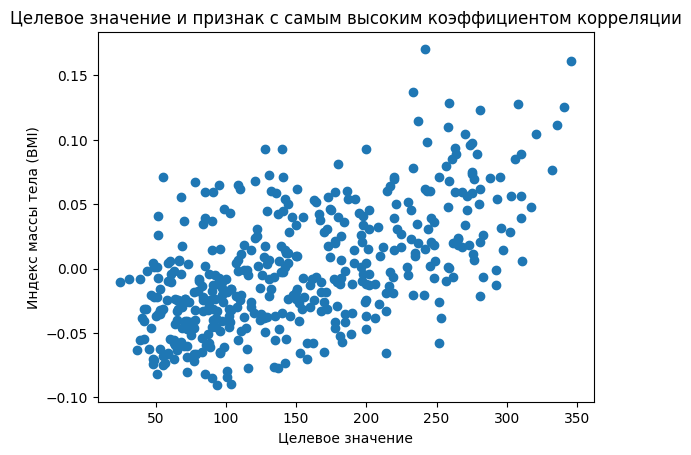

In [39]:
best_future = diabetes_df.corr()['target'].drop('target').idxmax()

fig, ax = plt.subplots()

ax.scatter(diabetes_df['target'], diabetes_df[best_future])

ax.set_xlabel("Целевое значение")
ax.set_ylabel("Индекс массы тела (BMI)")
ax.set_title("Целевое значение и признак с самым высоким коэффициентом корреляции")

plt.show()

6. Сформируйте набор признаков (X) из 5 признаков с самым высоким коэффициентом корреляции с целевым значением. Сформируйте набор для целевого значения (y).

In [66]:
correlations = diabetes_df.corr(numeric_only=True)["target"].drop("target")

top_columns = correlations.nlargest(5).index.tolist()

X = diabetes_df[top_columns]
y = diabetes_df["target"]

print("Пять выбранных признаков:")
for column in top_columns:
    print(f"{column}: корреляция = {correlations[column]:.3f}")

Пять выбранных признаков:
bmi: корреляция = 0.586
s5: корреляция = 0.566
bp: корреляция = 0.441
s4: корреляция = 0.430
s6: корреляция = 0.382


## Предсказательная модель

7. Разделите набор данных на два, одни для обучения модели другой для проверки. Тестовый набор должен содержать 25 процентов данных.

In [67]:
from sklearn.model_selection import train_test_split

X_train, X_test,y_train,y_test = train_test_split(X, y, train_size=0.75, random_state=60)

9. Выполните обучение модели.

In [71]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train, y_train)

print("Модель линейной регрессии успешно обучена.")
print(f"Количество признаков модели: {model.n_features_in_}")


Модель линейной регрессии успешно обучена.
Количество признаков модели: 5


## Проверка модели

9. Расчитайте Root mean squared error (RMSE)

In [72]:
from sklearn import metrics

y_predict = model.predict(X_test)

comparison_df = pd.DataFrame(
    {
        "Реальное значение": y_test.to_numpy(),
        "Предсказание модели": y_predict
    },
    index=y_test.index
)

comparison_df["Абсолютная ошибка"] = (
    comparison_df["Реальное значение"] -
    comparison_df["Предсказание модели"]
).abs()

print("Сравнение реальных значений и предсказаний:")
display(comparison_df.head(5).round(2))

rmse = np.sqrt(metrics.mean_squared_error(y_test, y_predict))

print(f"\nRMSE модели: {rmse:.2f}")

Сравнение реальных значений и предсказаний:


,Реальное значение,Предсказание модели,Абсолютная ошибка
195,122.0,179.20,57.20
39,90.0,154.54,64.54
164,214.0,151.16,62.84
292,84.0,95.40,11.40
433,72.0,84.62,12.62



RMSE модели: 54.66
Чем меньше RMSE, тем меньше ошибки предсказаний на тех же данных.


10. Расчитайте R² (коэффициент детерминации)

In [73]:
r2 = metrics.r2_score(y_test, y_predict)

print(f"Коэффициент детерминации R²: {r2:.3f}")

if r2 > 0:
    print("Модель лучше базового предсказания средним значением "
          "на этих тестовых данных.")
elif r2 == 0:
    print("Модель примерно соответствует базовому предсказанию "
          "средним значением.")
else:
    print("Модель хуже базового предсказания средним значением "
          "на этих тестовых данных.")

Коэффициент детерминации R²: 0.505
Модель лучше базового предсказания средним значением на этих тестовых данных.


## Вопросы для защиты

## Вопросы

### 1. Какие типы машинного обучения вы знаете?

Основные типы машинного обучения:

- **Обучение с учителем** — модель обучается на примерах, для которых известны правильные ответы. Примеры задач: предсказание стоимости жилья и определение спама.
- **Обучение без учителя** — правильные ответы заранее не указаны. Модель ищет закономерности и группы в данных.
- **Частично контролируемое обучение** — часть примеров имеет правильные ответы, а часть нет.
- **Обучение с подкреплением** — система учится выбирать действия, получая вознаграждение или штраф за результат.

### 2. Чем отличается обучение с учителем и без учителя?

При обучении с учителем модели предоставляют входные данные и правильные ответы. Она учится предсказывать эти ответы для новых примеров.

При обучении без учителя правильные ответы не предоставляются. Модель самостоятельно ищет структуру данных, например объединяет похожие объекты в группы.

В лабораторной работе используется обучение с учителем, потому что для каждого образца известен целевой показатель `target`.

### 3. Чем пакетное обучение отличается от динамического?

**Пакетное обучение** — модель обучают сразу на подготовленном наборе данных. Чтобы учесть новые данные, обычно запускают обучение заново.

**Динамическое, или потоковое, обучение** — модель обновляется постепенно по мере поступления новых данных.

Например, модель пакетного обучения можно периодически переобучать на новой истории продаж, а модель потокового обучения может обновляться по мере получения новых заказов.

### 4. Чем обучение на основе образцов отличается от обучения на основе модели?

При обучении на основе образцов система сохраняет примеры и использует их сходство с новым объектом для получения ответа.

При обучении на основе модели система строит математическую модель закономерностей в данных, а затем использует её для предсказаний.

В этой лабораторной используется второй подход: линейная регрессия подбирает коэффициенты формулы для прогнозирования `target`.

### 5. Что такое линейная регрессия?

Линейная регрессия — метод машинного обучения, который оценивает числовое значение на основе одного или нескольких признаков.

При одном признаке формула имеет вид:

`y = k * x + b`

При нескольких признаках прогноз рассчитывается по линейной комбинации этих признаков.

В лабораторной линейная регрессия использует пять характеристик набора Diabetes, чтобы предсказать целевой показатель прогрессирования заболевания.

### 6. Что такое градиентный спуск?

Градиентный спуск — метод постепенного улучшения параметров модели. На каждом шаге параметры изменяются в направлении уменьшения функции ошибки.

Его можно представить как поиск самой низкой точки на склоне: мы делаем шаги, стараясь уменьшить ошибку модели.

При этом стандартный `LinearRegression()` из scikit-learn решает задачу наименьших квадратов и не требует явно запускать градиентный спуск в коде этой лабораторной.

### 7. Как правильно обрабатывать категориальные признаки?

Категориальные признаки обозначают группы или категории, а не обычные числовые величины.

Один из распространённых способов обработки — **one-hot encoding**: для разных категорий создаются отдельные столбцы со значениями 0 и 1.

В pandas для этого можно использовать:

`pd.get_dummies(df, columns=['название_столбца'])`

Нельзя бездумно заменять категории числами, если у этих чисел нет реального порядка. Например, кодирование цветов числами 1, 2 и 3 может создать ложное впечатление, что один цвет больше или меньше другого.

В наборе Diabetes признак `sex` уже представлен числовым кодированием, поэтому его тип в pandas может быть числовым, хотя по смыслу это категориальный признак.

### 8. Что такое матрица корреляции?

Матрица корреляции — таблица коэффициентов, которая показывает силу и направление линейной связи между парами признаков.

Коэффициент корреляции находится в диапазоне от -1 до 1:

- значение около 1 указывает на сильную положительную связь;
- значение около -1 указывает на сильную отрицательную связь;
- значение около 0 указывает на слабую или отсутствующую линейную связь.

Корреляция не доказывает причинно-следственную связь между признаками.

В лабораторной матрица корреляции используется для выбора признаков, связанных с `target`.

### 9. Что показывает метрика RMSE?

RMSE (Root Mean Squared Error) — корень из средней квадратичной ошибки предсказаний.

Метрика показывает, насколько далеко предсказания модели отклоняются от реальных значений. Большие ошибки сильнее влияют на результат из-за возведения отклонений в квадрат.

RMSE измеряется в тех же единицах, что и целевой показатель. Чем меньше RMSE, тем лучше предсказания при сравнении моделей на одной и той же задаче и одинаковых тестовых данных.

RMSE, равный нулю, означает полное совпадение предсказаний с реальными значениями.

### 10. Что показывает метрика R²?

R², или коэффициент детерминации, показывает, насколько хорошо модель предсказывает значения по сравнению с базовым прогнозом, использующим среднее целевого показателя.

- R² = 1 — идеальные предсказания.
- R² около 0 — модель примерно не лучше базового прогноза средним значением.
- R² меньше 0 — модель хуже базового прогноза на рассматриваемых данных.

R² не является процентом правильных предсказаний. При оценке модели полезно рассматривать его вместе с RMSE.